# 서울시 무더위쉼터 최적 입지 분석

기존 성동구 AED 분석 코드를 **Python/Jupyter용으로 재구성**한 노트북입니다.

분석 흐름은 다음과 같습니다.

1. 서울시 행정동 경계 및 보행 네트워크 구축
2. 고령 유동인구 수요지, 기존 무더위쉼터, 신규 후보지 스냅
3. 네트워크 최단거리 계산
4. 기존 접근성 평가
5. **MCLP (`p=250` (예비))**
6. **p-median (`p=250` (예비))**
7. ** 형평성 MCLP ( p = 250) (예비) **
8. 세 모형의 커버율·인구가중 평균 접근거리·선정 입지 비교

> **중요:** `COVERAGE_DISTANCE_M`와 고령 유동인구 가중치 컬럼은 데이터센터에서 실제 데이터를 확인한 뒤 설정합니다.


In [1]:
# 필요한 패키지
# 설치가 필요한 경우 아래 주석을 해제해서 실행
# %pip install pandas numpy geopandas shapely pyproj networkx scipy matplotlib pulp openpyxl

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt

from shapely import wkt
from shapely.geometry import Point
from scipy.spatial import cKDTree

import pulp

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)


In [2]:
import time
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.lines import Line2D
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import coo_matrix
from scipy.spatial import cKDTree
from shapely import wkt
from shapely.geometry import Point

warnings.filterwarnings("ignore", category=UserWarning)

# 한글 글꼴. 설치된 것 중 먼저 찾은 것을 쓴다.
installed = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "AppleGothic"]:
    if font_name in installed:
        plt.rcParams["font.family"] = font_name
        break
else:
    print("한글 글꼴을 찾지 못했다. 그림의 한글이 깨지면 font_name 목록에 설치된 글꼴 이름을 추가한다.")
plt.rcParams["axes.unicode_minus"] = False

# 색. 서울 EDA와 같은 값이다. 같은 역할에는 같은 색을 쓴다.
INK, INK_SUB, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, LAND, BORDER, GRID = "#fcfcfb", "#f3f2ee", "#c3c2b7", "#e1e0d9"
BLUE = "#2a78d6"     # 기본 계열. 모형 그림에서는 MCLP
ORANGE = "#eb6834"   # 강조. 모형 그림에서는 형평성 MCLP, 공통 입지 지도에서는 신규 선정
AQUA = "#1baf7a"     # 세 번째 계열. 모형 그림에서는 p-median
GRAY = "#b5b3aa"     # 배경 역할
ORANGE_RAMP = ["#f6bfa6", "#eb6834", "#a83c12"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BORDER, "axes.labelcolor": INK_SUB, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_SUB, "axes.titlelocation": "left",
})



MODELS = ["MCLP", "형평성 MCLP", "p-median"]
MODEL_COLOR = {"MCLP": BLUE, "형평성 MCLP": ORANGE, "p-median": AQUA}
MODEL_FILE = {"MCLP": "MCLP", "형평성 MCLP": "형평성MCLP", "p-median": "p-median"}

## 0. 분석 설정

아래 경로와 컬럼명만 실제 파일에 맞게 수정하면 됩니다.

- `P = 250`: 2025년 서울시 실제 추가 지정 규모를 준용한 시나리오
- `COVERAGE_DISTANCE_M`: MCLP 서비스 기준거리. 최종 분석 전 문헌·정책 근거를 통해 확정
- 수요 가중치: 데이터센터에서 확인한 60대 이상 유동인구 컬럼 사용


In [3]:
# ============================================================
# 0. 경로 및 분석 설정
# ============================================================


BASE_DIR = Path(r"upload")  ## 로컬 파일 경로 (데이터 안심 구역 내의 경로로 변경)

NETWORK_PATH = BASE_DIR / "SeoulNetwork.csv"
ADM_GU_PATH = BASE_DIR / "SeoulBoundary.shp"
EXISTING_PATH = BASE_DIR / "SeoulCoolingCenter.csv"
CANDIDATE_PATH = BASE_DIR / "SeoulCandidateFacility.csv"


DEMAND_PATH = BASE_DIR / "SeoulPopulation7to9.csv"  ## 이거는 가서 받아야 하는 데이터이므로 다른 데이터로 연습용으로 한번 실행해보자

ANALYSIS_CRS = 5179
GEOGRAPHIC_CRS = 4326

P = 250
COVERAGE_DISTANCE_M = None

SNAP_CHECK_THRESHOLD_M = 100

CLIP_NETWORK = True
NETWORK_BUFFER_M = 500

EXISTING_LON_COL = "경도"
EXISTING_LAT_COL = "위도"

CANDIDATE_LON_COL = "경도"
CANDIDATE_LAT_COL = "위도"

DEMAND_LON_COL = "경도"  # 이전 : 경도 
DEMAND_LAT_COL = "위도"  # 이전 : 위도

WEIGHT_COL = "population"
WEIGHT_COLS = []

# 예시:
# WEIGHT_COLS = ["남자60대이상유동인구", "여자60대이상유동인구"]


## 1. 보조 함수

In [4]:
def read_vector(path, crs_if_missing=None):
    gdf = gpd.read_file(path)
    if gdf.crs is None and crs_if_missing is not None:
        gdf = gdf.set_crs(crs_if_missing)
    return gdf


def read_point_csv(path, lon_col, lat_col, encoding="utf-8-sig"):
    try:
        df = pd.read_csv(path, encoding=encoding)
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding="cp949")

    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")
    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")
    df = df.dropna(subset=[lon_col, lat_col]).copy()

    return gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
        crs=GEOGRAPHIC_CRS
    )


def ensure_points(gdf):
    out = gdf.copy()
    geom_types = set(out.geometry.geom_type.dropna().unique())
    if geom_types and geom_types.issubset({"Polygon", "MultiPolygon"}):
        out["geometry"] = out.representative_point()
    return out


def snap_points_to_nodes(points_gdf, nodes_gdf):
    pts = ensure_points(points_gdf).to_crs(nodes_gdf.crs).copy()

    node_xy = np.column_stack([
        nodes_gdf.geometry.x.to_numpy(),
        nodes_gdf.geometry.y.to_numpy()
    ])
    pt_xy = np.column_stack([
        pts.geometry.x.to_numpy(),
        pts.geometry.y.to_numpy()
    ])

    tree = cKDTree(node_xy)
    dist, idx = tree.query(pt_xy, k=1)

    pts["network_node"] = nodes_gdf.iloc[idx]["node_id"].to_numpy()
    pts["snap_distance_m"] = dist
    return pts


def print_snap_summary(gdf, label, threshold=100):
    s = gdf["snap_distance_m"]
    print(f"\\n[{label}]")
    print(s.describe())
    print(f"{threshold}m 초과: {(s > threshold).sum()}개")


def _endpoint_from_geometry(geom, start=True):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "LineString":
        coords = list(geom.coords)
        return Point(coords[0] if start else coords[-1])

    if geom.geom_type == "MultiLineString":
        parts = list(geom.geoms)
        target = parts[0] if start else parts[-1]
        coords = list(target.coords)
        return Point(coords[0] if start else coords[-1])

    return None


def make_weight(df, weight_col=None, weight_cols=None):
    out = df.copy()

    if weight_col is not None:
        if weight_col not in out.columns:
            raise KeyError(f"가중치 컬럼을 찾을 수 없습니다: {weight_col}")
        out["weight"] = pd.to_numeric(out[weight_col], errors="coerce")

    elif weight_cols:
        missing = [c for c in weight_cols if c not in out.columns]
        if missing:
            raise KeyError(f"가중치 컬럼을 찾을 수 없습니다: {missing}")
        out["weight"] = (
            out[weight_cols]
            .apply(pd.to_numeric, errors="coerce")
            .sum(axis=1, min_count=1)
        )

    else:
        print("수요 데이터 컬럼:")
        print(list(out.columns))
        raise ValueError(
            "WEIGHT_COL 또는 WEIGHT_COLS를 설정한 뒤 다시 실행하세요."
        )

    out["weight"] = out["weight"].fillna(0)
    return out


def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    return np.average(values[mask], weights=weights[mask])


def weighted_coverage(covered, weights):
    covered = np.asarray(covered, dtype=bool)
    weights = np.asarray(weights, dtype=float)
    return weights[covered].sum() / weights.sum()


## 2. 행정구 경계 불러오기

In [5]:
adm_GU = read_vector(ADM_GU_PATH).to_crs(ANALYSIS_CRS)

print(adm_GU.crs)
print("행정구 수:", len(adm_GU))
display(adm_GU.head())


EPSG:5179
행정구 수: 25


,BASE_DATE,SIGUNGU_CD,SIGUNGU_NM,geometry
0,20250630,11010,종로구,"POLYGON ((953683.828 1959209.871, 953665.283 1..."
1,20250630,11020,중구,"POLYGON ((957890.386 1952616.746, 957909.908 1..."
2,20250630,11030,용산구,"POLYGON ((953114.222 1950746.999, 953114.218 1..."
3,20250630,11040,성동구,"POLYGON ((959381.838 1952723.894, 959416.042 1..."
4,20250630,11050,광진구,"POLYGON ((964825.058 1952633.25, 964875.581 19..."


## 3. 서울시 보행 네트워크 구축

기존 AED 분석과 동일한 서울시 자치구별 도보 네트워크 CSV를 사용합니다.

- LINK: 시작노드, 종료노드, 링크 길이
- NODE: 노드 WKT
- 누락된 노드 좌표는 연결 LINK의 시작·끝 좌표로 복원
- 금천구 경계에 buffer를 두어 네트워크를 잘라 계산량을 줄임
- 가장 큰 연결요소만 사용


In [6]:
try:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="cp949",
        dtype=str,
        low_memory=False
    )
except UnicodeDecodeError:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="utf-8-sig",
        dtype=str,
        low_memory=False
    )

print("네트워크 원자료:", network_raw.shape)
display(network_raw.head())


네트워크 원자료: (491082, 23)


,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,읍면동코드,읍면동명,고가도로,지하철네트워크,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자
0,LINK,NaN,0,NaN,LINESTRING(126.96228683933481 37.5997378248954...,227523,1111,128414,128415,30.6370,1111000000,종로구,1111018600,신영동,0,0,0,0,0,0,0,0,2026-10-04 14:38:11.0
1,NODE,POINT(127.0099078298054 37.57668182537195),150733,0,NaN,0,NaN,NaN,NaN,NaN,1111000000,종로구,1111017400,창신동,NaN,NaN,NaN,NaN,0,0,NaN,NaN,2026-10-04 14:40:10.0
2,LINK,NaN,0,NaN,LINESTRING(126.99506871423829 37.5794324300485...,254542,1111,164485,164079,36.2740,1111000000,종로구,1111013000,와룡동,0,0,0,0,0,0,0,0,2026-10-04 14:38:29.0
3,LINK,NaN,0,NaN,LINESTRING(126.99336207048539 37.5902478559539...,15352,1111,135248,135225,14.0290,1111000000,종로구,1111017300,명륜3가,0,0,0,0,0,0,0,0,2026-10-04 14:36:13.0
4,LINK,NaN,0,NaN,LINESTRING(126.98204417605007 37.5802825342201...,56080,1111,133443,133444,34.8850,1111000000,종로구,1111014300,화동,0,0,0,0,0,0,0,0,2026-10-04 14:36:40.0


네트워크 원자료: (491082, 23)


,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,읍면동코드,읍면동명,고가도로,지하철네트워크,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자
0,LINK,NaN,0,NaN,LINESTRING(126.96228683933481 37.5997378248954...,227523,1111,128414,128415,30.6370,1111000000,종로구,1111018600,신영동,0,0,0,0,0,0,0,0,2026-10-04 14:38:11.0
1,NODE,POINT(127.0099078298054 37.57668182537195),150733,0,NaN,0,NaN,NaN,NaN,NaN,1111000000,종로구,1111017400,창신동,NaN,NaN,NaN,NaN,0,0,NaN,NaN,2026-10-04 14:40:10.0
2,LINK,NaN,0,NaN,LINESTRING(126.99506871423829 37.5794324300485...,254542,1111,164485,164079,36.2740,1111000000,종로구,1111013000,와룡동,0,0,0,0,0,0,0,0,2026-10-04 14:38:29.0
3,LINK,NaN,0,NaN,LINESTRING(126.99336207048539 37.5902478559539...,15352,1111,135248,135225,14.0290,1111000000,종로구,1111017300,명륜3가,0,0,0,0,0,0,0,0,2026-10-04 14:36:13.0
4,LINK,NaN,0,NaN,LINESTRING(126.98204417605007 37.5802825342201...,56080,1111,133443,133444,34.8850,1111000000,종로구,1111014300,화동,0,0,0,0,0,0,0,0,2026-10-04 14:36:40.0


전체 링크 수: 279016
시각화 가능한 링크 수: 279016
좌표계: EPSG:4326


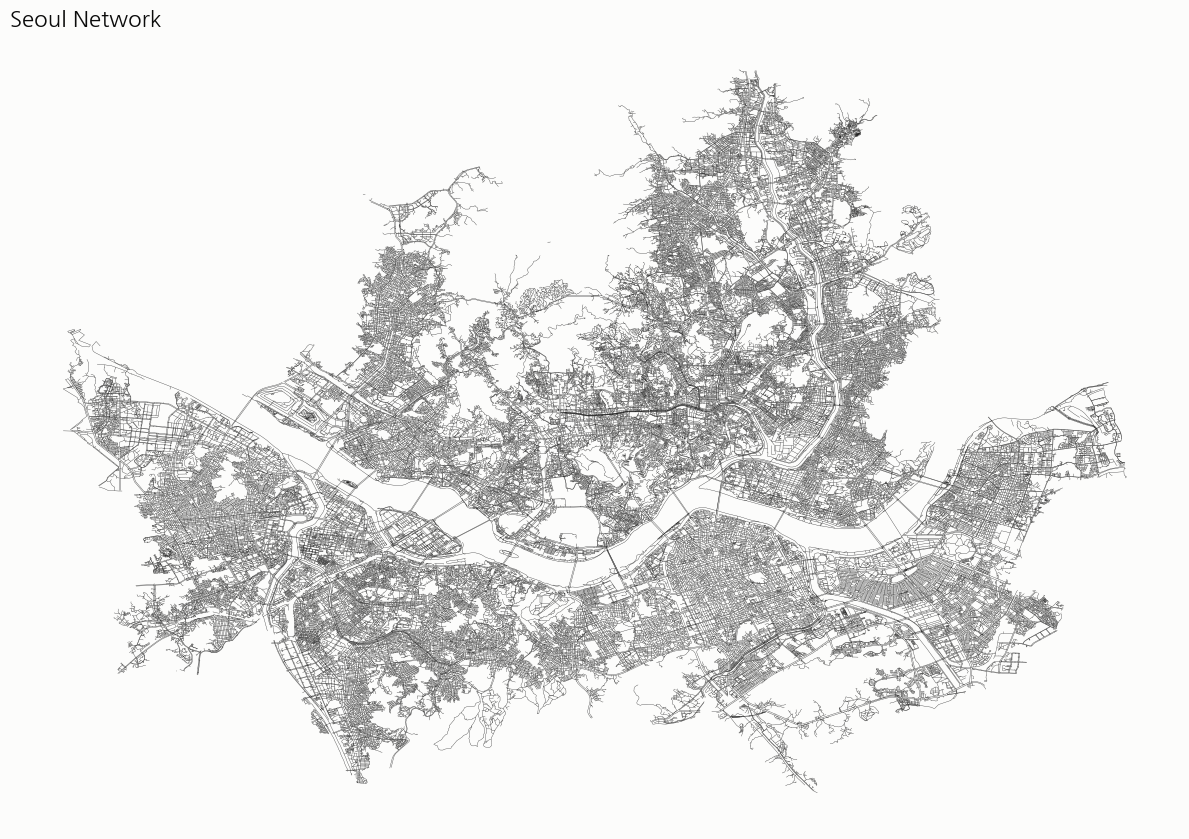

In [7]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt

# 1. 네트워크 데이터 불러오기
try:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="cp949",
        dtype=str,
        low_memory=False
    )
except UnicodeDecodeError:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="utf-8-sig",
        dtype=str,
        low_memory=False
    )

print("네트워크 원자료:", network_raw.shape)
display(network_raw.head())


# 2. LINK 데이터만 추출
network_links = network_raw.loc[
    (network_raw["노드링크 유형"] == "LINK")
    & network_raw["링크 WKT"].notna()
    & (network_raw["링크 WKT"].str.strip() != "")
].copy()


# 3. WKT 문자열을 공간 데이터로 변환
def parse_wkt(value):
    try:
        return wkt.loads(value)
    except Exception:
        return None


network_links["geometry"] = network_links["링크 WKT"].map(parse_wkt)
network_links = network_links.dropna(subset=["geometry"])


# 4. GeoDataFrame 생성
network_gdf = gpd.GeoDataFrame(
    network_links,
    geometry="geometry",
    crs="EPSG:4326"
)

print("전체 링크 수:", len(network_links))
print("시각화 가능한 링크 수:", len(network_gdf))
print("좌표계:", network_gdf.crs)


# 5. 도로 네트워크 시각화
fig, ax = plt.subplots(figsize=(12, 12))

network_gdf.plot(
    ax=ax,
    color="black",
    linewidth=0.25,
    alpha=0.8
)

ax.set_title("Seoul Network", fontsize=16)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
node_rows = network_raw.loc[
    (network_raw["노드링크 유형"] == "NODE")
    & network_raw["노드 WKT"].notna()
    & (network_raw["노드 WKT"] != "")
].copy()

node_rows["geometry"] = node_rows["노드 WKT"].map(wkt.loads)

node_gdf = gpd.GeoDataFrame(
    {
        "node_id": node_rows["노드 ID"].astype(str),
        "node_type": node_rows.get("노드 유형 코드"),
    },
    geometry=node_rows["geometry"],
    crs=GEOGRAPHIC_CRS
).drop_duplicates("node_id")

link_rows = network_raw.loc[
    (network_raw["노드링크 유형"] == "LINK")
    & network_raw["시작노드 ID"].notna()
    & network_raw["종료노드 ID"].notna()
    & network_raw["링크 길이"].notna()
].copy()

link_rows["from"] = link_rows["시작노드 ID"].astype(str)
link_rows["to"] = link_rows["종료노드 ID"].astype(str)
link_rows["length"] = pd.to_numeric(link_rows["링크 길이"], errors="coerce")
link_rows = link_rows.loc[
    np.isfinite(link_rows["length"]) & (link_rows["length"] > 0)
].copy()

graph_node_ids = set(link_rows["from"]) | set(link_rows["to"])
known_ids = set(node_gdf["node_id"])
missing_ids = graph_node_ids - known_ids

if missing_ids:
    recovery = link_rows.loc[
        link_rows["링크 WKT"].notna()
        & (
            link_rows["from"].isin(missing_ids)
            | link_rows["to"].isin(missing_ids)
        )
    ].copy()

    recovered = {}

    for _, row in recovery.iterrows():
        try:
            geom = wkt.loads(row["링크 WKT"])
        except Exception:
            continue

        if row["from"] in missing_ids and row["from"] not in recovered:
            recovered[row["from"]] = _endpoint_from_geometry(geom, start=True)

        if row["to"] in missing_ids and row["to"] not in recovered:
            recovered[row["to"]] = _endpoint_from_geometry(geom, start=False)

    rec_df = pd.DataFrame(
        [(nid, geom) for nid, geom in recovered.items() if geom is not None],
        columns=["node_id", "geometry"]
    )

    if len(rec_df):
        rec_gdf = gpd.GeoDataFrame(
            rec_df,
            geometry="geometry",
            crs=GEOGRAPHIC_CRS
        )
        rec_gdf["node_type"] = None
        node_gdf = pd.concat(
            [node_gdf, rec_gdf[["node_id", "node_type", "geometry"]]],
            ignore_index=True
        )
        node_gdf = gpd.GeoDataFrame(
            node_gdf, geometry="geometry", crs=GEOGRAPHIC_CRS
        ).drop_duplicates("node_id")

node_gdf = node_gdf.to_crs(ANALYSIS_CRS)

remaining_missing = graph_node_ids - set(node_gdf["node_id"])
print("좌표 미복원 네트워크 노드:", len(remaining_missing))


좌표 미복원 네트워크 노드: 0


In [9]:
if CLIP_NETWORK:
    study_geom = adm_GU.geometry.union_all().buffer(NETWORK_BUFFER_M)
    keep_nodes = set(
        node_gdf.loc[node_gdf.geometry.intersects(study_geom), "node_id"]
    )

    link_use = link_rows.loc[
        link_rows["from"].isin(keep_nodes)
        & link_rows["to"].isin(keep_nodes)
    ].copy()
else:
    link_use = link_rows.copy()

G = nx.Graph()

for _, row in link_use.iterrows():
    u = str(row["from"])
    v = str(row["to"])
    length = float(row["length"])

    if G.has_edge(u, v):
        if length < G[u][v]["length"]:
            G[u][v]["length"] = length
    else:
        G.add_edge(u, v, length=length)

largest_cc = max(nx.connected_components(G), key=len)
G = G.subgraph(largest_cc).copy()

node_gdf = node_gdf.loc[
    node_gdf["node_id"].isin(G.nodes)
].drop_duplicates("node_id").copy()

print("그래프 노드:", G.number_of_nodes())
print("그래프 링크:", G.number_of_edges())
print("공간 노드:", len(node_gdf))


그래프 노드: 212986
그래프 링크: 276585
공간 노드: 212986


## 4. 기존 무더위쉼터·후보지·수요지 불러오기

현재 파일 형식에 맞게 경로와 좌표 컬럼명을 수정합니다.


In [10]:
existing = read_point_csv(
    EXISTING_PATH,
    EXISTING_LON_COL,
    EXISTING_LAT_COL
).to_crs(ANALYSIS_CRS)

candidate = read_point_csv(
    CANDIDATE_PATH,
    CANDIDATE_LON_COL,
    CANDIDATE_LAT_COL
).to_crs(ANALYSIS_CRS)

demand = read_point_csv(
    DEMAND_PATH,
    DEMAND_LON_COL,
    DEMAND_LAT_COL
).to_crs(ANALYSIS_CRS)

print("기존 무더위쉼터:", len(existing))
print("원 후보지:", len(candidate))
print("원 수요지:", len(demand))
print("수요지 CRS:", demand.crs)
print("수요지 좌표 범위:", demand.total_bounds)

기존 무더위쉼터: 4092
원 후보지: 1143
원 수요지: 222218
수요지 CRS: EPSG:5179
수요지 좌표 범위: [ 935083.991787 1936679.147389  972033.991787 1966979.147389]


### 4-1. 고령 유동인구 가중치 생성

In [11]:
demand = make_weight(
    demand,
    weight_col=WEIGHT_COL,
    weight_cols=WEIGHT_COLS
)

demand = demand.loc[
    np.isfinite(demand["weight"]) & (demand["weight"] > 0)
].copy()

print("양(+)의 가중치를 가진 수요격자:", len(demand))
print("총 고령 유동수요:", demand["weight"].sum())
display(demand[['geometry', 'population', '경도', '위도','weight']].head())


양(+)의 가중치를 가진 수요격자: 221070
총 고령 유동수요: 12301573.73


,geometry,population,경도,위도,weight
0,POINT (935083.992 1950929.147),1.04,126.765035,37.555425,1.04
1,POINT (935133.992 1950929.147),0.77,126.765601,37.555429,0.77
2,POINT (935133.992 1950979.147),0.46,126.765597,37.555879,0.46
3,POINT (935183.992 1950879.147),0.75,126.766172,37.554982,0.75
4,POINT (935183.992 1950929.147),0.91,126.766167,37.555432,0.91


## 5. 네트워크 노드에 스냅

In [12]:
demand = snap_points_to_nodes(demand, node_gdf)
existing = snap_points_to_nodes(existing, node_gdf)
candidate = snap_points_to_nodes(candidate, node_gdf)

print_snap_summary(demand, "수요지", SNAP_CHECK_THRESHOLD_M)
print_snap_summary(existing, "기존 무더위쉼터", SNAP_CHECK_THRESHOLD_M)
print_snap_summary(candidate, "후보지", SNAP_CHECK_THRESHOLD_M)


\n[수요지]
count    221070.000000
mean         89.909117
std         184.347149
min           0.098495
25%          17.060157
50%          32.632592
75%          77.873889
max        2839.071645
Name: snap_distance_m, dtype: float64
100m 초과: 44763개
\n[기존 무더위쉼터]
count    4092.000000
mean       26.036295
std        17.430018
min         0.671890
25%        14.824027
50%        22.043200
75%        32.260718
max       222.716859
Name: snap_distance_m, dtype: float64
100m 초과: 25개
\n[후보지]
count    1143.000000
mean       26.684032
std        17.760431
min         3.089134
25%        15.483816
50%        22.482575
75%        32.983242
max       227.136137
Name: snap_distance_m, dtype: float64
100m 초과: 6개


## 6. 분석용 수요지·기존시설·후보지 정리

- 동일 네트워크 노드에 연결된 수요격자는 가중치를 합산
- 동일 네트워크 노드의 후보지는 하나만 남김
- 기존 무더위쉼터와 같은 노드의 후보지는 제거


In [13]:
graph_nodes = set(G.nodes)

existing_clean = existing.loc[
    existing["network_node"].isin(graph_nodes)
].copy()

existing_nodes = existing_clean["network_node"].drop_duplicates().tolist()

candidate_clean = (
    candidate.loc[candidate["network_node"].isin(graph_nodes)]
    .sort_values("snap_distance_m")
    .drop_duplicates("network_node", keep="first")
    .copy()
)

candidate_clean = candidate_clean.loc[
    ~candidate_clean["network_node"].isin(existing_nodes)
].copy()

candidate_clean = candidate_clean.reset_index(drop=True)
candidate_clean["candidate_id"] = [
    f"C{i:03d}" for i in range(1, len(candidate_clean) + 1)
]

# 서울시 자치구 경계의 컬럼명을 분석용 이름으로 정리
adm_gu = (
    adm_GU[["SIGUNGU_CD", "SIGUNGU_NM", "geometry"]]
    .rename(columns={
        "SIGUNGU_CD": "gu_code",
        "SIGUNGU_NM": "gu_name"
    })
    .to_crs(demand.crs)
    .copy()
)

# 수요점에 자치구 정보 결합
# 셀을 재실행해도 이전 지역 정보와 컬럼명이 충돌하지 않도록 제거
demand_with_gu = gpd.sjoin(
    demand.drop(
        columns=[
            "index_left", "index_right",
            "dong", "ADM_CD", "ADM_NM",
            "SIGUNGU_CD", "SIGUNGU_NM",
            "gu_code", "gu_name"
        ],
        errors="ignore"
    ),
    adm_gu,
    how="inner",
    predicate="within"
).drop(columns="index_right").copy()

# 같은 네트워크 노드라도 자치구가 다르면 별도 수요지로 유지
demand_model = (
    demand_with_gu.loc[
        demand_with_gu["network_node"].isin(graph_nodes)
    ]
    .groupby(["network_node", "gu_code"], as_index=False)
    .agg(
        gu_name=("gu_name", "first"),
        weight=("weight", "sum"),
        n_grid=("weight", "size")
    )
)

demand_model["demand_id"] = [
    f"D{i:04d}" for i in range(1, len(demand_model) + 1)
]

print("네트워크 노드 기준 통합 후 수요지:", len(demand_model))
print("경계자료의 자치구 수:", adm_gu["gu_code"].nunique())
print("분석 수요가 있는 자치구 수:", demand_model["gu_code"].nunique())
print("총 분석 수요 가중치:", (demand_model["weight"].sum()).round(2))


네트워크 노드 기준 통합 후 수요지: 117522
경계자료의 자치구 수: 25
분석 수요가 있는 자치구 수: 25
총 분석 수요 가중치: 12301350.42


In [14]:
candidate_clean.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1064 entries, 0 to 1063
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   시설유형             1064 non-null   object  
 1   시설명              1064 non-null   object  
 2   시구동              1064 non-null   object  
 3   시설수              1064 non-null   int64   
 4   상세주소             1064 non-null   object  
 5   위도               1064 non-null   float64 
 6   경도               1064 non-null   float64 
 7   좌표출처             1064 non-null   object  
 8   geometry         1064 non-null   geometry
 9   network_node     1064 non-null   object  
 10  snap_distance_m  1064 non-null   float64 
 11  candidate_id     1064 non-null   object  
dtypes: float64(3), geometry(1), int64(1), object(7)
memory usage: 99.9+ KB


## 7. 네트워크 최단거리 계산

- 기존 쉼터까지 거리는 `multi_source_dijkstra`로 한 번에 계산
- 후보지까지 거리는 후보지별 Dijkstra를 실행하여 행렬 생성


In [15]:
nearest_existing_dict = nx.multi_source_dijkstra_path_length(
    G,
    sources=existing_nodes,
    weight="length"
)

demand_nodes = demand_model["network_node"].tolist()

nearest_existing_m = np.array([
    nearest_existing_dict.get(n, np.inf)
    for n in demand_nodes
], dtype=float)

demand_model["nearest_existing_m"] = nearest_existing_m

print(demand_model["nearest_existing_m"].describe())
print(
    "기존 쉼터까지 인구가중 평균거리:",
    round(
        weighted_mean(
            demand_model["nearest_existing_m"],
            demand_model["weight"]
        ),
        2
    ),
    "m"
)


count    117522.000000
mean        299.273099
std         270.698618
min           0.000000
25%         143.996500
50%         238.485000
75%         369.699500
max        3507.647000
Name: nearest_existing_m, dtype: float64
기존 쉼터까지 인구가중 평균거리: 289.59 m


In [16]:
candidate_nodes = candidate_clean["network_node"].tolist()
demand_index_by_node = defaultdict(list)

for i, node in enumerate(demand_nodes):
    demand_index_by_node[node].append(i)

demand_node_set = set(demand_nodes)

demand_candidate_dist = np.full(
    (len(demand_model), len(candidate_clean)),
    np.inf,
    dtype=float
)

for j, source in enumerate(candidate_nodes):
    lengths = nx.single_source_dijkstra_path_length(
        G,
        source=source,
        weight="length"
    )

    for node in demand_node_set.intersection(lengths.keys()):
        d = lengths[node]
        for i in demand_index_by_node[node]:
            demand_candidate_dist[i, j] = d

    if (j + 1) % 50 == 0 or (j + 1) == len(candidate_nodes):
        print(f"후보지 거리계산: {j+1}/{len(candidate_nodes)}")

print("거리행렬 shape:", demand_candidate_dist.shape)


후보지 거리계산: 50/1064
후보지 거리계산: 100/1064
후보지 거리계산: 150/1064
후보지 거리계산: 200/1064
후보지 거리계산: 250/1064
후보지 거리계산: 300/1064
후보지 거리계산: 350/1064
후보지 거리계산: 400/1064
후보지 거리계산: 450/1064
후보지 거리계산: 500/1064
후보지 거리계산: 550/1064
후보지 거리계산: 600/1064
후보지 거리계산: 650/1064
후보지 거리계산: 700/1064
후보지 거리계산: 750/1064
후보지 거리계산: 800/1064
후보지 거리계산: 850/1064
후보지 거리계산: 900/1064
후보지 거리계산: 950/1064
후보지 거리계산: 1000/1064
후보지 거리계산: 1050/1064
후보지 거리계산: 1064/1064
거리행렬 shape: (117522, 1064)


## 8. 기존 무더위쉼터 접근성 평가

In [17]:
COVERAGE_DISTANCE_M = 219

if COVERAGE_DISTANCE_M is None:
    raise ValueError(
        "COVERAGE_DISTANCE_M를 먼저 설정하세요. "
        "예: COVERAGE_DISTANCE_M = 300"
    )

demand_model["existing_covered"] = (
    demand_model["nearest_existing_m"] <= COVERAGE_DISTANCE_M
).astype(int)

existing_coverage_rate = weighted_coverage(
    demand_model["existing_covered"].astype(bool),
    demand_model["weight"]
)

existing_mean_distance = weighted_mean(
    demand_model["nearest_existing_m"],
    demand_model["weight"]
)

print("커버 기준거리:", COVERAGE_DISTANCE_M, "m")
print("기존 고령 유동인구 커버율:", round(existing_coverage_rate * 100, 2), "%")
print("기존 인구가중 평균 접근거리:", round(existing_mean_distance, 2), "m")


커버 기준거리: 219 m
기존 고령 유동인구 커버율: 42.7 %
기존 인구가중 평균 접근거리: 289.59 m


## 9. MCLP

In [18]:
A = np.isfinite(demand_candidate_dist) & (
    demand_candidate_dist <= COVERAGE_DISTANCE_M
)

def solve_mclp(weights, existing_covered, coverage_matrix, p, msg=True):
    n_demand, n_candidate = coverage_matrix.shape

    if p > n_candidate:
        raise ValueError(f"p={p}가 후보지 수 {n_candidate}보다 큽니다.")

    model = pulp.LpProblem("MCLP", pulp.LpMaximize)

    x = {
        j: pulp.LpVariable(f"x_{j}", cat="Binary")
        for j in range(n_candidate)
    }
    y = {
        i: pulp.LpVariable(f"y_{i}", cat="Binary")
        for i in range(n_demand)
    }

    model += pulp.lpSum(weights[i] * y[i] for i in range(n_demand))
    model += pulp.lpSum(x[j] for j in range(n_candidate)) == p

    for i in range(n_demand):
        if existing_covered[i]:
            model += y[i] == 1
        else:
            js = np.flatnonzero(coverage_matrix[i])
            if len(js) == 0:
                model += y[i] == 0
            else:
                model += y[i] <= pulp.lpSum(x[j] for j in js)

    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    selected = [
        j for j in range(n_candidate)
        if pulp.value(x[j]) is not None and pulp.value(x[j]) > 0.5
    ]

    return model, status, selected


weights = demand_model["weight"].to_numpy(float)
existing_covered = demand_model["existing_covered"].to_numpy(bool)

model_mclp, status_mclp, selected_mclp_idx = solve_mclp(
    weights=weights,
    existing_covered=existing_covered,
    coverage_matrix=A,
    p=P,
    msg=True
)

print("MCLP status:", status_mclp)
print("선정 후보지 수:", len(selected_mclp_idx))


Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/kdata/.local/lib/python3.10/site-packages/pulp/apis/../solverdir/cbc/linux/i64/cbc /tmp/343824debed342e396c4335ba2877a50-pulp.mps -max -timeMode elapsed -solve -printingOptions all -solution /tmp/343824debed342e396c4335ba2877a50-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 117528 COLUMNS
At line 601270 RHS
At line 718794 BOUNDS
At line 837381 ENDATA
Problem MODEL has 117523 rows, 118586 columns and 129047 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 6.0147e+06 - 0.00 seconds
Cgl0002I 55525 variables fixed
Cgl0004I processed model has 1171 rows, 2129 columns (2129 integer (2127 of which binary)) and 4590 elements
Cbc0038I Initial state - 0 integers unsatisfied sum - 0
Cbc0038I Solution found of -6.0147e+06
Cbc0038I Cleaned solution of -6.0147e+06
Cbc0038I Before mini branch and b

In [19]:
mclp_covered = existing_covered.copy()

if selected_mclp_idx:
    mclp_covered |= A[:, selected_mclp_idx].any(axis=1)

mclp_coverage_rate = weighted_coverage(
    mclp_covered,
    weights
)

mclp_nearest_new = (
    np.min(demand_candidate_dist[:, selected_mclp_idx], axis=1)
    if selected_mclp_idx
    else np.full(len(demand_model), np.inf)
)

mclp_distance = np.minimum(
    demand_model["nearest_existing_m"].to_numpy(float),
    mclp_nearest_new
)

mclp_mean_distance = weighted_mean(
    mclp_distance,
    weights
)

selected_mclp = candidate_clean.iloc[selected_mclp_idx].copy()
selected_mclp["model"] = "MCLP"

print("MCLP 커버율:", round(mclp_coverage_rate * 100, 2), "%")
print("MCLP 평균 접근거리:", round(mclp_mean_distance, 2), "m")

display(selected_mclp)


MCLP 커버율: 48.89 %
MCLP 평균 접근거리: 263.55 m


,시설유형,시설명,시구동,시설수,상세주소,위도,경도,좌표출처,geometry,network_node,snap_distance_m,candidate_id,model
1,경로당,(장안동)현대아파트경로당,서울특별시 동대문구 장안동,1,서울특별시 동대문구 한천로 224 (장안동),37.580826,127.068513,ArcGIS 지오코딩(주소 지점 일치),POINT (961901.887 1953580.947),3703,3.097204,C002,MCLP
7,경로당,신계경로당,서울특별시 용산구,1,서울특별시 용산구 원효로 216,37.534523,126.967158,ArcGIS 지오코딩(주소 지점 일치),POINT (952923.607 1948489.749),177065,5.257596,C008,MCLP
9,경로당,보광동제3경로당,서울특별시 용산구,1,서울특별시 용산구 보광로32길 1,37.529317,126.998072,ArcGIS 지오코딩(주소 지점 일치),POINT (955651.715 1947897.136),161467,5.582187,C010,MCLP
15,경로당,경희궁자이2단지경로당,서울특별시 종로구 홍파동,1,"종로구 송월길 99 (홍파동, 경희궁자이2단지)",37.570042,126.962843,ArcGIS 지오코딩(주소 지점 일치),POINT (952564.893 1952432.559),128617,6.002447,C016,MCLP
19,도서관(작은도서관),운룡도서관,서울특별시 광진구 중곡동,1,서울특별시 광진구 자양로43길 85(중곡동),37.554198,127.089360,전국도서관표준데이터,POINT (963729.688 1950618.463),88389,6.312210,C020,MCLP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,경로당,대림아크로빌아파트,서울특별시 강남구,1,강남구 언주로 30길 13,37.488536,127.051416,ArcGIS 지오코딩(주소 지점 일치),POINT (960343.424 1943348.925),204088,75.733556,C1044,MCLP
1046,경로당,덕수궁롯데캐슬아파트,서울특별시 중구,1,"서소문로9길 28, 2층",37.563822,126.970556,ArcGIS 지오코딩(주소 지점 일치),POINT (953242.11 1951738.692),119050,79.937050,C1047,MCLP
1050,경로당,래미안대치팰리스2단지아파트,서울특별시 강남구,1,강남구 삼성로51길 35,37.495564,127.061403,ArcGIS 지오코딩(주소 지점 일치),POINT (961230.03 1944124.485),11163,85.935438,C1051,MCLP
1051,경로당,잠실I-SPACE,서울특별시 송파구 신천동,1,송파구 오금로 58 (신천동),37.516760,127.105465,ArcGIS 지오코딩(주소 지점 일치),POINT (965134.773 1946458.883),90702,87.202922,C1052,MCLP


## 10. p-median

각 수요지에 대해 **현재 가장 가까운 기존 쉼터보다 더 가까운 후보지**만 assignment 대상으로 남겨 계산량을 줄입니다.


In [20]:








def solve_pmedian_with_existing(
    weights,
    nearest_existing,
    candidate_dist,
    p,
    msg=True
):
    n_demand, n_candidate = candidate_dist.shape

    if p > n_candidate:
        raise ValueError(f"p={p}가 후보지 수 {n_candidate}보다 큽니다.")

    better = (
        np.isfinite(candidate_dist)
        & (candidate_dist < nearest_existing[:, None])
    )

    demand_idx, candidate_idx = np.where(better)
    pair_distance = candidate_dist[demand_idx, candidate_idx]

    n_pair = len(demand_idx)

    pair_list = defaultdict(list)
    for k, i in enumerate(demand_idx):
        pair_list[int(i)].append(k)

    model = pulp.LpProblem("p_median", pulp.LpMinimize)

    x = {
        j: pulp.LpVariable(f"x_{j}", cat="Binary")
        for j in range(n_candidate)
    }

    u = {
        i: pulp.LpVariable(
            f"u_{i}",
            lowBound=0,
            upBound=1,
            cat="Continuous"
        )
        for i in range(n_demand)
    }

    v = {
        k: pulp.LpVariable(
            f"v_{k}",
            lowBound=0,
            upBound=1,
            cat="Continuous"
        )
        for k in range(n_pair)
    }

    model += (
        pulp.lpSum(
            weights[i] * nearest_existing[i] * u[i]
            for i in range(n_demand)
        )
        +
        pulp.lpSum(
            weights[demand_idx[k]]
            * pair_distance[k]
            * v[k]
            for k in range(n_pair)
        )
    )

    model += pulp.lpSum(x[j] for j in range(n_candidate)) == p

    for k in range(n_pair):
        model += v[k] <= x[int(candidate_idx[k])]

    for i in range(n_demand):
        ks = pair_list.get(i, [])
        if ks:
            model += u[i] + pulp.lpSum(v[k] for k in ks) == 1
        else:
            model += u[i] == 1

    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    selected = [
        j for j in range(n_candidate)
        if pulp.value(x[j]) is not None and pulp.value(x[j]) > 0.5
    ]

    return model, status, selected


model_pmedian, status_pmedian, selected_pmedian_idx = solve_pmedian_with_existing(
    weights=weights,
    nearest_existing=demand_model["nearest_existing_m"].to_numpy(float),
    candidate_dist=demand_candidate_dist,
    p=P,
    msg=True
)

print("p-median status:", status_pmedian)
print("선정 후보지 수:", len(selected_pmedian_idx))


Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/kdata/.local/lib/python3.10/site-packages/pulp/apis/../solverdir/cbc/linux/i64/cbc /tmp/9f413e34992941858cda925fa8f0b90f-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /tmp/9f413e34992941858cda925fa8f0b90f-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 157945 COLUMNS
At line 554209 RHS
At line 712150 BOUNDS
At line 871154 ENDATA
Problem MODEL has 157940 rows, 159003 columns and 239837 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 3.21115e+09 - 0.00 seconds
Cgl0004I processed model has 48841 rows, 49901 columns (1061 integer (1061 of which binary)) and 114341 elements
Cbc0038I Initial state - 0 integers unsatisfied sum - 0
Cbc0038I Solution found of 3.21115e+09
Cbc0038I Relaxing continuous gives 3.21115e+09
Cbc0038I Before mini branch and bound, 1061 integers at bo

In [21]:
pmedian_nearest_new = (
    np.min(demand_candidate_dist[:, selected_pmedian_idx], axis=1)
    if selected_pmedian_idx
    else np.full(len(demand_model), np.inf)
)

pmedian_distance = np.minimum(
    demand_model["nearest_existing_m"].to_numpy(float),
    pmedian_nearest_new
)

pmedian_mean_distance = weighted_mean(
    pmedian_distance,
    weights
)

pmedian_covered = pmedian_distance <= COVERAGE_DISTANCE_M
pmedian_coverage_rate = weighted_coverage(
    pmedian_covered,
    weights
)

selected_pmedian = candidate_clean.iloc[selected_pmedian_idx].copy()
selected_pmedian["model"] = "p-median"

print("p-median 커버율:", round(pmedian_coverage_rate * 100, 2), "%")
print("p-median 평균 접근거리:", round(pmedian_mean_distance, 2), "m")

display(selected_pmedian)


p-median 커버율: 48.42 %
p-median 평균 접근거리: 261.04 m


,시설유형,시설명,시구동,시설수,상세주소,위도,경도,좌표출처,geometry,network_node,snap_distance_m,candidate_id,model
0,경로당,신반포16차아파트 경로당,서울특별시 서초구,1,서초구 잠원로 157,37.517279,127.010223,ArcGIS 지오코딩(주소 지점 일치),POINT (956718.441 1946555.919),95947,3.089134,C001,p-median
1,경로당,(장안동)현대아파트경로당,서울특별시 동대문구 장안동,1,서울특별시 동대문구 한천로 224 (장안동),37.580826,127.068513,ArcGIS 지오코딩(주소 지점 일치),POINT (961901.887 1953580.947),3703,3.097204,C002,p-median
6,경로당,서광(아),서울특별시 강서구,1,강서구 양천로 27길 129,37.579619,126.819605,ArcGIS 지오코딩(주소 지점 일치),POINT (939923.42 1953577.073),159730,5.081077,C007,p-median
7,경로당,신계경로당,서울특별시 용산구,1,서울특별시 용산구 원효로 216,37.534523,126.967158,ArcGIS 지오코딩(주소 지점 일치),POINT (952923.607 1948489.749),177065,5.257596,C008,p-median
9,경로당,보광동제3경로당,서울특별시 용산구,1,서울특별시 용산구 보광로32길 1,37.529317,126.998072,ArcGIS 지오코딩(주소 지점 일치),POINT (955651.715 1947897.136),161467,5.582187,C010,p-median
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049,경로당,가양8단지(아),서울특별시 강서구,1,강서구 허준로 176,37.562127,126.856969,ArcGIS 지오코딩(주소 지점 일치),POINT (943209.258 1951613.216),21440,85.573754,C1050,p-median
1050,경로당,래미안대치팰리스2단지아파트,서울특별시 강남구,1,강남구 삼성로51길 35,37.495564,127.061403,ArcGIS 지오코딩(주소 지점 일치),POINT (961230.03 1944124.485),11163,85.935438,C1051,p-median
1052,경로당,LH강남아이파크아파트,서울특별시 강남구,1,강남구 자곡로 175,37.474417,127.101360,ArcGIS 지오코딩(주소 지점 일치),POINT (964752.044 1941762.653),201986,88.736656,C1053,p-median
1062,도서관(공공도서관),우면도서관,서울특별시 서초구,1,서울특별시 서초구 양재대로2길 110,37.461531,127.032070,전국도서관표준데이터,POINT (958618.276 1940361.252),214470,147.463781,C1063,p-median


## 11. 형평성 MCLP

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix, vstack, csr_matrix

## 형평성 모형 최적화 안내
기존 셀을 희소 HiGHS 모형으로 교체했습니다. scipy >= 1.9 필요. 기존 호출·반환변수는 유지됩니다. `model_equity_mclp`는 PuLP 객체 대신 진단 딕셔너리입니다.
기존 커버 수요는 상수로 처리하고, 커버 불가능 수요는 지역 총수요에 유지합니다. 같은 자치구·동일 후보 커버 패턴을 합칩니다. 시설선택만 이진변수입니다.
1단계: 최저 자치구 커버율 최대화. 2단계: 그 값을 1e-7 비율(0.00001%p) 허용오차 내 유지하며 전체 커버 최대화. 각 단계 기본 제한은 600초이며 미완료 시 오류로 중단합니다. 함수 기본값 time_limit을 늘리거나 None으로 바꿀 수 있습니다.
다른 전처리 및 모델은 수정하지 않았습니다. 실제 수요 좌표계와 스냅거리를 반드시 확인하세요.


In [23]:
import numpy as np
import pandas as pd
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix, vstack, csr_matrix


def solve_equity_mclp(weights, gus, existing_covered, coverage_matrix, p,
                      basic_optimum_people, eta=0.95, msg=True,
                      time_limit=600, q_tolerance=1e-7):
    """Sparse HiGHS MILP. Same four return values as the old function.

    Stage 1 maximizes minimum GU coverage; stage 2 maximizes total coverage
    while retaining stage-1 q within q_tolerance (fraction, not percent).
    Raises on time limit / non-optimal result; never silently reports an
    incumbent as an optimum. time_limit applies separately to each stage.
    """
    w = np.asarray(weights, dtype=float)
    groups = np.asarray(gus)
    base = np.asarray(existing_covered, dtype=bool)
    A = np.asarray(coverage_matrix, dtype=bool)
    if A.ndim != 2:
        raise ValueError('coverage_matrix must be 2-D')
    n, m = A.shape
    if any(len(a) != n for a in (w, groups, base)):
        raise ValueError('Input lengths do not agree')
    if not np.isfinite(w).all() or (w <= 0).any():
        raise ValueError('Use finite strictly positive demand weights')
    if pd.isna(groups).any() or n == 0:
        raise ValueError('Empty demand or missing region codes')
    if not isinstance(p, (int, np.integer)) or not 0 <= p <= m:
        raise ValueError('p must be an integer between 0 and candidate count')
    if not 0 < eta <= 1 or not np.isfinite(basic_optimum_people):
        raise ValueError('Invalid eta or baseline optimum')
    if not 0 <= basic_optimum_people <= w.sum() * (1 + 1e-9):
        raise ValueError('Invalid baseline optimum')
    if not 0 <= q_tolerance <= 1e-5:
        raise ValueError('q_tolerance must lie in [0, 1e-5]')

    # Work with population shares to keep coefficients well scaled.
    wn = w / w.sum()
    codes, labels = pd.factorize(groups, sort=False)
    ng = len(labels)
    totals = np.bincount(codes, weights=wn, minlength=ng)
    fixed = np.bincount(codes[base], weights=wn[base], minlength=ng)
    active = ~base & A.any(axis=1)

    # Same GU + identical candidate coverage -> one aggregated demand unit.
    # Process one GU at a time to limit temporary memory.
    rows_A, unit_w, unit_gu = [], [], []
    for g in range(ng):
        idx = np.flatnonzero(active & (codes == g))
        if not len(idx):
            continue
        packed = np.packbits(A[idx], axis=1)
        _, first, inverse = np.unique(packed, axis=0,
                                      return_index=True, return_inverse=True)
        rows_A.append(csr_matrix(A[idx[first]], dtype=float))
        unit_w.extend(np.bincount(inverse, weights=wn[idx]))
        unit_gu.extend([g] * len(first))
    B = vstack(rows_A, format='csr') if rows_A else csr_matrix((0, m))
    uw = np.asarray(unit_w)
    ug = np.asarray(unit_gu, dtype=int)
    r = len(uw)
    # x binary; y and q continuous. Upper-bound coverage is sufficient:
    # for any fixed x, setting y to the actual 0/1 coverage can only improve
    # both coverage objectives and all lower-bound constraints.
    nv = m + r + 1
    rr, cc = B.nonzero()
    row_parts = [rr, np.arange(r), np.full(m, r),
                 r + 1 + ug, r + 1 + np.arange(ng),
                 np.full(r, r + 1 + ng)]
    col_parts = [cc, m + np.arange(r), np.arange(m),
                 m + np.arange(r), np.full(ng, nv - 1),
                 m + np.arange(r)]
    val_parts = [-np.ones(len(rr)), np.ones(r), np.ones(m),
                 -uw / totals[ug], np.ones(ng), -uw]
    mat = coo_matrix((np.concatenate(val_parts),
                      (np.concatenate(row_parts), np.concatenate(col_parts))),
                     shape=(r + ng + 2, nv)).tocsc()
    floor = eta * basic_optimum_people / w.sum()
    lb = np.r_[np.full(r, -np.inf), p,
               np.full(ng + 1, -np.inf)]
    ub = np.r_[np.zeros(r), p, fixed / totals, fixed.sum() - floor]
    integrality = np.r_[np.ones(m, dtype=int), np.zeros(r + 1, dtype=int)]
    opts = {'disp': msg, 'mip_rel_gap': 0.0, 'presolve': True}
    if time_limit is not None:
        opts['time_limit'] = float(time_limit)
    def run(c, upper_q_floor=None):
        lower = np.zeros(nv)
        if upper_q_floor is not None:
            lower[-1] = upper_q_floor
        result = milp(c, integrality=integrality,
                      bounds=Bounds(lower, np.ones(nv)),
                      constraints=LinearConstraint(mat, lb, ub), options=opts)
        if result.status != 0 or result.x is None:
            raise RuntimeError(
                'Equity solve not certified optimal: ' + result.message +
                '; increase time_limit or use time_limit=None. '
                'Do not label a time-limited incumbent optimal.')
        return result
    print(f'Equity compression: {n:,} demands -> {r:,} variable units; '
          f'{m:,} binary variables; {mat.shape[0]:,} constraints; '
          f'{mat.nnz:,} nonzeros')
    c1 = np.zeros(nv); c1[-1] = -1
    first_result = run(c1)
    q_star = float(first_result.x[-1])
    c2 = np.zeros(nv); c2[m:m+r] = -uw
    second_result = run(c2, max(0.0, q_star - q_tolerance))
    xs = second_result.x[:m]
    if np.max(np.abs(xs - np.rint(xs)), initial=0) > 1e-5:
        raise RuntimeError('Non-integral facility selection')
    selected = np.flatnonzero(xs > 0.5).tolist()
    if len(selected) != p:
        raise RuntimeError('Wrong selected facility count')
    actual = base.copy()
    if selected:
        actual |= A[:, selected].any(axis=1)
    actual_total = float(wn[actual].sum())
    actual_by_gu = np.bincount(codes[actual], weights=wn[actual], minlength=ng)
    actual_q = float((actual_by_gu / totals).min())
    if actual_total < floor - 1e-7 or actual_q < q_star - q_tolerance - 1e-7:
        raise RuntimeError('Post-solve coverage verification failed')
    diagnostics = {'stage1': first_result, 'stage2': second_result,
                   'q_star': q_star, 'actual_q': actual_q,
                   'covered_people': actual_total * w.sum(),
                   'binary_variables': m, 'aggregated_units': r,
                   'constraints': mat.shape[0], 'nonzeros': mat.nnz}
    return diagnostics, 'Optimal', selected, actual_q


ETA = 0.95

# ------------------------------------------------------------
# 기존 MCLP가 달성한 최대 커버 인구 계산
# ------------------------------------------------------------

if status_mclp != "Optimal":
    raise RuntimeError(
        "기존 MCLP가 Optimal 상태가 아니므로 "
        "형평성 MCLP와 비교할 수 없습니다."
    )

basic_covered_for_equity = existing_covered.copy()

if selected_mclp_idx:
    basic_covered_for_equity |= (
        A[:, selected_mclp_idx].any(axis=1)
    )

basic_optimum_people = float(
    weights[basic_covered_for_equity].sum()
)

# ------------------------------------------------------------
# 형평성 MCLP 실행
# ------------------------------------------------------------

model_equity_mclp, status_equity_mclp, selected_equity_mclp_idx, equity_q = (
    solve_equity_mclp(
        weights=weights,
        gus=demand_model["gu_code"].to_numpy(),
        existing_covered=existing_covered,
        coverage_matrix=A,
        p=P,
        basic_optimum_people=basic_optimum_people,
        eta=ETA,
        msg=True
    )
)

print("형평성 MCLP status:", status_equity_mclp)
print("선정 후보지 수:", len(selected_equity_mclp_idx))

Equity compression: 117,522 demands -> 1,294 variable units; 1,064 binary variables; 1,321 constraints; 6,657 nonzeros
Running HiGHS 1.2.0 [date: 2021-07-09, git hash: n/a]
Copyright (c) 2022 ERGO-Code under MIT licence terms
Presolving model
1304 rows, 2359 cols, 6039 nonzeros
1304 rows, 2255 cols, 5933 nonzeros

Solving MIP model with:
   1304 rows
   2255 cols (957 binary, 3 integer, 0 implied int., 1295 continuous)
   5933 nonzeros

        Nodes      |    B&B Tree     |            Objective Bounds              |  Dynamic Constraints |       Work      
     Proc. InQueue |  Leaves   Expl. | BestBound       BestSol              Gap |   Cuts   InLp Confl. | LpIters     Time

         0       0         0   0.00%   -0.3582788257   inf                  inf        0      0      0         0     0.0s

Solving report
  Status            Optimal
  Primal bound      -0.358278825665
  Dual bound        -0.358278825665
  Gap               0%
  Solution status   feasible
                    -0.3

In [24]:
equity_mclp_covered = existing_covered.copy()

if selected_equity_mclp_idx:
    equity_mclp_covered |= (
        A[:, selected_equity_mclp_idx].any(axis=1)
    )

equity_mclp_coverage_rate = weighted_coverage(
    equity_mclp_covered,
    weights
)

equity_mclp_nearest_new = (
    np.min(
        demand_candidate_dist[
            :,
            selected_equity_mclp_idx
        ],
        axis=1
    )
    if selected_equity_mclp_idx
    else np.full(len(demand_model), np.inf)
)

equity_mclp_distance = np.minimum(
    demand_model["nearest_existing_m"].to_numpy(float),
    equity_mclp_nearest_new
)

equity_mclp_mean_distance = weighted_mean(
    equity_mclp_distance,
    weights
)

selected_equity_mclp = (
    candidate_clean
    .iloc[selected_equity_mclp_idx]
    .copy()
)

selected_equity_mclp["model"] = "형평성 MCLP"

# 효율성 유지 제약 사후 검증
equity_covered_people = float(
    weights[equity_mclp_covered].sum()
)

tolerance = 1e-5 * max(1.0, basic_optimum_people)

if (
    equity_covered_people + tolerance
    < ETA * basic_optimum_people
):
    raise RuntimeError(
        "형평성 MCLP 결과가 eta 효율성 제약을 위반했습니다."
    )

print(
    "형평성 MCLP 커버율:",
    round(equity_mclp_coverage_rate * 100, 2),
    "%"
)

print(
    "형평성 MCLP 평균 접근거리:",
    round(equity_mclp_mean_distance, 2),
    "m"
)

display(selected_equity_mclp)

형평성 MCLP 커버율: 48.6 %
형평성 MCLP 평균 접근거리: 264.1 m


,시설유형,시설명,시구동,시설수,상세주소,위도,경도,좌표출처,geometry,network_node,snap_distance_m,candidate_id,model
1,경로당,(장안동)현대아파트경로당,서울특별시 동대문구 장안동,1,서울특별시 동대문구 한천로 224 (장안동),37.580826,127.068513,ArcGIS 지오코딩(주소 지점 일치),POINT (961901.887 1953580.947),3703,3.097204,C002,형평성 MCLP
7,경로당,신계경로당,서울특별시 용산구,1,서울특별시 용산구 원효로 216,37.534523,126.967158,ArcGIS 지오코딩(주소 지점 일치),POINT (952923.607 1948489.749),177065,5.257596,C008,형평성 MCLP
9,경로당,보광동제3경로당,서울특별시 용산구,1,서울특별시 용산구 보광로32길 1,37.529317,126.998072,ArcGIS 지오코딩(주소 지점 일치),POINT (955651.715 1947897.136),161467,5.582187,C010,형평성 MCLP
12,경로당,현대한강아파트경로당,서울특별시 용산구,1,서울특별시 용산구 이촌로34길 29,37.523161,126.958542,ArcGIS 지오코딩(주소 지점 일치),POINT (952155.053 1947233.58),63248,5.730361,C013,형평성 MCLP
19,도서관(작은도서관),운룡도서관,서울특별시 광진구 중곡동,1,서울특별시 광진구 자양로43길 85(중곡동),37.554198,127.089360,전국도서관표준데이터,POINT (963729.688 1950618.463),88389,6.312210,C020,형평성 MCLP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1036,경로당,롯데캐슬아이비(아),서울특별시 영등포구 여의도동,1,국제금융로 86(여의도동 43-4),37.520206,126.931800,ArcGIS 지오코딩(주소 지점 일치),POINT (949790.073 1946919.677),215213,72.030886,C1037,형평성 MCLP
1043,경로당,대림아크로빌아파트,서울특별시 강남구,1,강남구 언주로 30길 13,37.488536,127.051416,ArcGIS 지오코딩(주소 지점 일치),POINT (960343.424 1943348.925),204088,75.733556,C1044,형평성 MCLP
1046,경로당,덕수궁롯데캐슬아파트,서울특별시 중구,1,"서소문로9길 28, 2층",37.563822,126.970556,ArcGIS 지오코딩(주소 지점 일치),POINT (953242.11 1951738.692),119050,79.937050,C1047,형평성 MCLP
1050,경로당,래미안대치팰리스2단지아파트,서울특별시 강남구,1,강남구 삼성로51길 35,37.495564,127.061403,ArcGIS 지오코딩(주소 지점 일치),POINT (961230.03 1944124.485),11163,85.935438,C1051,형평성 MCLP


## 11. MCLP vs 형평성 MCLP vs p-median 

In [25]:
def calculate_min_gu_coverage_pct(
    covered,
    weights,
    gus
):
    covered = np.asarray(covered, dtype=bool)
    weights = np.asarray(weights, dtype=float)
    gus = np.asarray(gus)

    coverage_df = pd.DataFrame({
        "gu": gus,
        "population": weights,
        "covered_population": weights * covered.astype(int)
    })

    gu_coverage = (
        coverage_df
        .groupby("gu", as_index=False)
        .agg(
            population=("population", "sum"),
            covered_population=("covered_population", "sum")
        )
    )

    gu_coverage["coverage_rate"] = (
        gu_coverage["covered_population"]
        / gu_coverage["population"]
    )

    return gu_coverage["coverage_rate"].min() * 100


# 행정구 정보
gus = demand_model["gu_code"].to_numpy()

# 모델별 최저 행정구 커버율
existing_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        existing_covered,
        weights,
        gus
    )
)

mclp_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        mclp_covered,
        weights,
        gus
    )
)

equity_mclp_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        equity_mclp_covered,
        weights,
        gus
    )
)

pmedian_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        pmedian_covered,
        weights,
        gus
    )
)


# 모델 비교표
comparison = pd.DataFrame({
    "model": [
        "기존",
        "MCLP",
        "형평성 MCLP",
        "p-median"
    ],
    "coverage_rate_pct": [
        existing_coverage_rate * 100,
        mclp_coverage_rate * 100,
        equity_mclp_coverage_rate * 100,
        pmedian_coverage_rate * 100
    ],
    "weighted_mean_distance_m": [
        existing_mean_distance,
        mclp_mean_distance,
        equity_mclp_mean_distance,
        pmedian_mean_distance
    ],
    "min_gu_coverage_rate_pct": [
        existing_min_gu_coverage_pct,
        mclp_min_gu_coverage_pct,
        equity_mclp_min_gu_coverage_pct,
        pmedian_min_gu_coverage_pct
    ]
}).round(2)

comparison

,model,coverage_rate_pct,weighted_mean_distance_m,min_gu_coverage_rate_pct
0,기존,42.70,289.59,23.22
1,MCLP,48.89,263.55,33.47
2,형평성 MCLP,48.60,264.10,35.83
3,p-median,48.42,261.04,32.47


## 12. 선정 입지 지도

In [27]:
w = demand_model["weight"].to_numpy(float)
n_candidate = len(candidate_clean)
e = np.array([nearest_existing_dict.get(n, np.inf) for n in demand_model["network_node"]])
D = np.full((len(demand_model), n_candidate), np.inf)

In [28]:
def context_layers(ax):
    """모든 입지 지도에 공통으로 깔리는 층. 행정동, 후보시설, 기존 쉼터."""
    base_map(ax)
    dong_labels(ax)
    ax.scatter(cand_clean.geometry.x, cand_clean.geometry.y, s=14, facecolors="none",
               edgecolors=GRAY, linewidths=0.8, zorder=4)
    # 기존 쉼터는 회색으로 칠한다. 파랑은 MCLP 선정지 색이라 겹치지 않게 한다.
    ax.scatter(existing_clean.geometry.x, existing_clean.geometry.y, s=22, color=INK_MUTED,
               edgecolors=SURFACE, linewidths=0.8, zorder=5)


In [29]:
def base_map(ax):
    dong.plot(ax=ax, facecolor=LAND, edgecolor=BORDER, linewidth=0.6, zorder=1)
    ax.set_aspect("equal")
    ax.set_axis_off()



def evaluate(selected):
    """선정 후보지 목록을 받아 세 지표를 계산한다. 기존 쉼터는 항상 포함한다."""
    dist = e if len(selected) == 0 else np.minimum(e, D[:, selected].min(axis=1))
    covered = dist <= COVERAGE_DISTANCE_M
    
    return {
        "coverage_pct": w[covered].sum() / w.sum() * 100,
        "mean_dist_m": weighted_mean(dist, w),
        "covered_people": w[covered].sum(),
    }



def context_layers(ax):
    """모든 입지 지도에 공통으로 깔리는 층. 행정동, 후보시설, 기존 쉼터."""
    base_map(ax)
    dong_labels(ax)
    ax.scatter(candidate_clean.geometry.x, candidate_clean.geometry.y, s=14, facecolors="none",
               edgecolors=GRAY, linewidths=0.8, zorder=4)
    # 기존 쉼터는 회색으로 칠한다. 파랑은 MCLP 선정지 색이라 겹치지 않게 한다.
    ax.scatter(existing_clean.geometry.x, existing_clean.geometry.y, s=22, color=INK_MUTED,
               edgecolors=SURFACE, linewidths=0.8, zorder=5)


def context_handles():
    return [
        Line2D([], [], marker="o", linestyle="", markersize=6, color=INK_MUTED, label=f"기존 쉼터 ({len(existing_clean)}곳)"),
        Line2D([], [], marker="o", linestyle="", markersize=6, markerfacecolor="none",
               markeredgecolor=GRAY, label=f"후보시설 ({len(candidate_clean)}곳)"),
    ]




In [ ]:
selected = {}
p = 250
sel_m = solve_mclp(
    weights=weights,
    existing_covered=existing_covered,
    coverage_matrix=A,
    p=P,
    msg=True
)

r_m = evaluate(sel_m)
sel_e = solve_equity(p, r_m["covered_people"])
sel_p = solve_pmedian(p)

for model, sel in (("MCLP", sel_m), ("형평성 MCLP", sel_e), ("p-median", sel_p)):
        if len(sel) != p:
            raise RuntimeError(f"{model} p={p}: 선정 수가 {len(sel)}개다")
        selected[(model, p)] = sel

In [39]:
sel_m.dim()

AttributeError: 'tuple' object has no attribute 'dim'

In [34]:
for model in MODELS:
    sel = candidate_clean.iloc[selected[(model, p)]]
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    context_layers(ax)
    ax.scatter(sel.geometry.x, sel.geometry.y, s=75, color=MODEL_COLOR[model], edgecolors=SURFACE, linewidths=1.5, zorder=6)
    handles = context_handles() + [
        Line2D([], [], marker="o", linestyle="", markersize=8, color=MODEL_COLOR[model], label=f"신규 선정 ({p}곳)")]
    ax.legend(handles=handles, title=f"{model}, 기준거리 {COVERAGE_DISTANCE_M}m", frameon=False,
              loc="lower left", fontsize=9, title_fontsize=9, labelcolor=INK_SUB)
    save(fig, f"02_선정입지_{MODEL_FILE[model]}_p{p}.png")
    plt.show()



# 보조 함수 : context_layers(ax), context_handles()
# cand_clean = candidate_clean 
# node = network_node
# snap_m = snap_distance_m

# demand = demand_model

# MODEL_COLOR = {"MCLP": BLUE, "형평성 MCLP": ORANGE, "p-median": AQUA}
# SURFACE, LAND, BORDER, GRID = "#fcfcfb", "#f3f2ee", "#c3c2b7", "#e1e0d9"
# MODELS = ["MCLP", "형평성 MCLP", "p-median"]
# MODEL_COLOR = {"MCLP": BLUE, "형평성 MCLP": ORANGE, "p-median": AQUA}
# MODEL_FILE = {"MCLP": "MCLP", "형평성 MCLP": "형평성MCLP", "p-median": "p-median"}

KeyError: ('MCLP', 250)

In [ ]:
# ============================================================
# 1. 기본 MCLP 결과
# ============================================================

fig, ax = plt.subplots(figsize=(8.5, 8.5))

adm_GU.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

candidate_clean.plot(
    ax=ax,
    color="gray",
    markersize=8,
    alpha=0.25,
    label = 'Candidate Place'
)

"""existing_clean.plot(
    ax=ax,
    color="blue",
    marker="^",
    markersize=20,
    alpha=0.6
)"""

if len(selected_mclp):
    selected_mclp.plot(
        ax=ax,
        color="red",
        marker="o",
        markersize=45,
        label ='Optimized Place'
    )

ax.set_title("MCLP New Place")
ax.set_axis_off()

plt.tight_layout()
plt.legend(loc = 'upper right')
plt.savefig("eda_output/MCLP New Place_P=300.png")
plt.show()


# ============================================================
# 2. 형평성 MCLP 결과
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

adm_GU.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

candidate_clean.plot(
    ax=ax,
    color="gray",
    markersize=8,
    alpha=0.25,
    label = 'Candidate Place'
)

"""existing_clean.plot(
    ax=ax,
    color="blue",
    marker="^",
    markersize=20,
    alpha=0.6
)"""

if len(selected_equity_mclp):
    selected_equity_mclp.plot(
        ax=ax,
        color="green",
        marker="o",
        markersize=45,
        label = 'Optimized Place'
    )

ax.set_title("Equity MCLP New Place")
ax.set_axis_off()

plt.tight_layout()
plt.legend(loc = 'upper right')
plt.savefig("eda_output/Equity MCLP New Place_P=300.png")
plt.show()


# ============================================================
# 3. p-median 결과
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

adm_GU.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

candidate_clean.plot(
    ax=ax,
    color="gray",
    markersize=8,
    alpha=0.25,
    label = 'Candidate Place'
)

""" existing_clean.plot(
    ax=ax,
    color="blue",
    marker="^",
    markersize=20,
    alpha=0.6
)"""

if len(selected_pmedian):
    selected_pmedian.plot(
        ax=ax,
        color="orange",
        marker="o",
        markersize=45,
        label = 'Optimized Place'
    )

ax.set_title("p-median New Place")
ax.set_axis_off()

plt.tight_layout()
plt.legend(loc = 'upper right')
plt.savefig("eda_output/p_median New Place_P=300.png")
plt.show()

In [ ]:
df1 = set(selected_equity_mclp['상세주소'])
df2 = set(selected_mclp['상세주소'])
df3 = set(selected_pmedian['상세주소'])

common = df1 & df2 & df3

only_equity_mclp = df1 - df2 - df3
only_mclp = df2 - df1 - df3
only_pmedian = df3 - df1 - df2

common_mclp_and_equity_mclp = df1 & df2
common_mclp_and_pmedian = df2 & df3
common_equity_mclp_and_pmedian = df1 & df3

equity_mclp_exclude_mclp = df1 - df2
equity_mclp_exclude_pmedian = df1 - df3

mclp_exclude_equity_mclp = df2 - df1
mclp_exclude_pmedian = df2 - df3

pmedian_exclude_equity_mclp = df3 - df1
pmedian_exclude_mclp = df3 - df2





print('3가지 방법론 공통 장소 :', len(common))
print('형평성 MCLP만 있는 장소 :', len(only_equity_mclp))
print('MCLP만 있늕 장소:', len(only_mclp))
print('P-median만 있는 장소:', len(only_pmedian))

print('')
print('MCLP & 형평성 MCLP 공통 장소:', len(common_mclp_and_equity_mclp))
print('MCLP & P-median 공통 장소:', len(common_mclp_and_pmedian))
print('형평성 MCLP & P-median 공통 장소:',len(common_equity_mclp_and_pmedian))
print('')

print("형평성 MCLP(MCLP와 비교)만 있는 장소",len(equity_mclp_exclude_mclp))
print("형평성 MCLP(P-median과 비교)만 있는 장소", len(equity_mclp_exclude_pmedian))

print("MCLP(형평성 MCLP와 비교)만 있는 장소", len(mclp_exclude_equity_mclp))
print("MCLP(P-median과 비교)만 있는 장소", len(mclp_exclude_pmedian))

print("P-median(형평성 MCLP와 비교)만 있는 장소", len(pmedian_exclude_equity_mclp))
print("P-median(MCLP와 비교)만 있는 장소", len(pmedian_exclude_mclp))

1. 시각화를 많이 해놨으면 좋겠는데 그게 조금 부족함 (ex : EDA라고 부를만한 게 딱히 없음)
2. 형평성 MCLP 코드 부재 - 용진
3. 평가 지표 없음 
- 모델 3개마다의 장점 존재 (목적함수)
- 각 모델의 유리한 평가 지표 ? 를 보여줬음 
- 객관적 평가 지표를 못 찾았음
4. 서울 전체 확장 ? --> p를 확정적으로 지어야 함 (계산량 엄청 많음)
** p를 찾자 (전년도에 얼마나 지었는지 참고하는게 좋아보임) 

해야 할 것 

1. 코드 합치기 (안심구역에서랑 우리 로컬에서 돌린거랑 합쳐야 함)
- 시각화 추가 
2. 평가 지표 코드 짜기 + 형평성 MCLP - 용진 
3. 서울시로 확장한다고 가정하면 / 후보지 '전처리' 사전 작업 필요 - 동근, 광일
- ** 서울시로 확장하면 p를 명확하게 정해야 함 
- 데이터는 용진이 보내줌 

왜 60대 이상을 목표로 했는지 필요성에 대한 언급 
- 무더위 쉼터 중 경로당 비율이 가장 높고 경로당 같은 경우 자주 이용하는 나이대가 60대 이상임을 보여주면 좋지 않을까